# Example 2: Ordinary Crank--Nicolson Method

For the classical case $$ \alpha=1 $$,
$$
u_t=c_d u_{xx}+c_su(1-u)(u-a),
\qquad -1\leq x\leq1.
$$

For Example 2,
$$
u(x,0)=e^{-(x+1)},
$$

with Neumann boundary conditions

$$
u_x(-1,t)=-1,
\qquad
u_x(1,t)=-e^{-2}.
$$

The working parameters are

$$
c_d=1,\qquad c_s=50,\qquad a=0.5.
$$



In this notebook, Crank--Nicolson is used for the diffusion term, while the nonlinear reaction term is evaluated explicitly at the current time level. This keeps the method separate from the later quasilinearized matrix approach.


## 1. Crank--Nicolson Discretization

For the diffusion term,

$$
u_{xx}(x_i,t)
\approx
\frac{u_{i+1}-2u_i+u_{i-1}}{\Delta x^2}.
$$

Crank--Nicolson averages the diffusion term between \(t_n\) and \(t_{n+1}\). Let

$$
r=\frac{c_d\Delta t}{2\Delta x^2}.
$$

Then the interior equation is
$$
-r\,u_{i-1}^{n+1}
+
(1+2r)u_i^{n+1}
-
r\,u_{i+1}^{n+1}
=
r\,u_{i-1}^{n}
+
(1-2r)u_i^{n}
+
r\,u_{i+1}^{n}
+
\Delta t\,F(u_i^n),
$$

where

$$
$$

The nonlinear reaction term is kept explicit here so that each time step only requires a linear solve.


## 2. Neumann Boundary Conditions

The second-order one-sided approximations are

$$
u_x(-1,t)
\approx
\frac{-3u_0+4u_1-u_2}{2\Delta x},
$$

and

$$
u_x(1,t)
\approx
\frac{3u_N-4u_{N-1}+u_{N-2}}{2\Delta x}.
$$

Using the prescribed boundary conditions gives

$$
3u_0-4u_1+u_2=2\Delta x,
$$

and

$$
u_{N-2}-4u_{N-1}+3u_N
=
-\frac{2\Delta x}{e^2}.
$$

These two equations are placed directly into the first and last rows of the Crank--Nicolson linear system.


## 3. Imports


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline


## 4. Reaction Term


In [2]:
def reaction(u, cs, a):
    return cs * u * (1 - u) * (u - a)


## Crank - Nicolson Solve Function


In [4]:
def solve_example2_cn(
    Nx=80,
    cd=1.0,
    cs=50.0,
    a=0.5,
    t_final=0.5,
    dt=0.001
):
    # --------------------------------------------------
    # Spatial grid
    # --------------------------------------------------
    x_left = -1.0
    x_right = 1.0

    x = np.linspace(x_left, x_right, Nx + 1)
    dx = x[1] - x[0]

    # --------------------------------------------------
    # Initial condition
    # --------------------------------------------------
    u = np.exp(-(x + 1))

    # --------------------------------------------------
    # Time grid
    # --------------------------------------------------
    Nt = int(np.ceil(t_final / dt))
    dt = t_final / Nt

    r = cd * dt / (2 * dx**2)

    # --------------------------------------------------
    # Build constant Crank--Nicolson matrices
    # --------------------------------------------------
    A = np.zeros((Nx + 1, Nx + 1))
    B = np.zeros((Nx + 1, Nx + 1))

    # Left Neumann boundary:
    # 3u0 - 4u1 + u2 = 2dx
    A[0, 0] = 3.0
    A[0, 1] = -4.0
    A[0, 2] = 1.0

    # Interior rows
    for i in range(1, Nx):
        A[i, i - 1] = -r
        A[i, i] = 1 + 2*r
        A[i, i + 1] = -r

        B[i, i - 1] = r
        B[i, i] = 1 - 2*r
        B[i, i + 1] = r

    # Right Neumann boundary:
    # u_{N-2} - 4u_{N-1} + 3uN = -2dx/e^2
    A[-1, -3] = 1.0
    A[-1, -2] = -4.0
    A[-1, -1] = 3.0

    # --------------------------------------------------
    # Midpoint history
    # --------------------------------------------------
    mid_index = np.argmin(np.abs(x))

    time_values = [0.0]
    midpoint_values = [u[mid_index]]

    # --------------------------------------------------
    # Time stepping
    # --------------------------------------------------
    for n in range(Nt):

        rhs = B @ u

        # Explicit nonlinear reaction on interior points
        rhs[1:-1] += dt * reaction(
            u[1:-1],
            cs,
            a
        )

        # Boundary equations
        rhs[0] = 2 * dx
        rhs[-1] = -2 * dx / np.exp(2)

        # Solve for the new time level
        u = np.linalg.solve(A, rhs)

        time_values.append((n + 1) * dt)
        midpoint_values.append(u[mid_index])

    return (
        x,
        u,
        np.array(time_values),
        np.array(midpoint_values),
        dx,
        dt,
        r
    )


## Main Crank-Nicolson Solution

The computation is run to

$$
T=0.5
$$

because the maximum-error comparison is made at $$ t=0.5$$

The midpoint graph uses only

$$
0\leq t\leq0.1 .
$$


In [5]:
x, u, time_values, midpoint_values, dx, dt, r = solve_example2_cn(
    Nx=80,
    cd=1.0,
    cs=50.0,
    a=0.5,
    t_final=0.5,
    dt=0.001
)

mask_01 = time_values <= 0.1 + 1e-12

print("dx =", dx)
print("dt =", dt)
print("r =", r)
print("Starting midpoint =", midpoint_values[0])
print("Midpoint at t = 0.1 =", midpoint_values[mask_01][-1])
print("Final midpoint at t = 0.5 =", midpoint_values[-1])
print("Minimum u at t = 0.5 =", np.min(u))
print("Maximum u at t = 0.5 =", np.max(u))
print("Contains NaN =", np.isnan(u).any())
print("Contains infinity =", np.isinf(u).any())


dx = 0.025000000000000022
dt = 0.001
r = 0.7999999999999986
Starting midpoint = 0.36787944117144233
Midpoint at t = 0.1 = 0.27381931429738665
Final midpoint at t = 0.5 = 0.2902667442517251
Minimum u at t = 0.5 = -0.021865676627615526
Maximum u at t = 0.5 = 1.1548234341249346
Contains NaN = False
Contains infinity = False


## Midpoint Graph \(u(0,t)\)




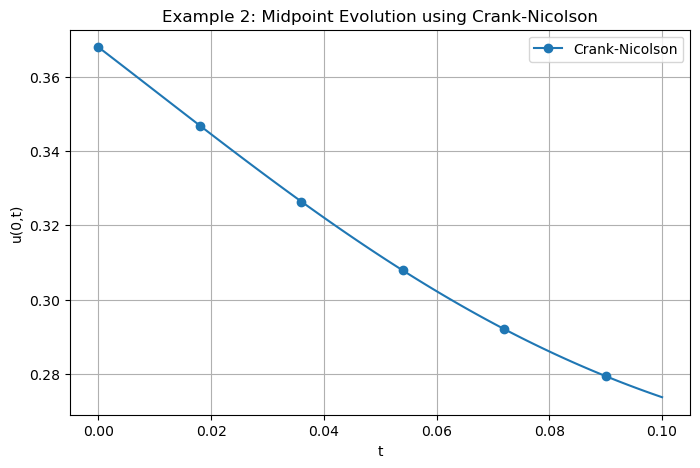

In [7]:
mask_01 = time_values <= 0.1 + 1e-12

plt.figure(figsize=(8, 5))

plt.plot(
    time_values[mask_01],
    midpoint_values[mask_01],
    label="Crank-Nicolson", marker="o",markevery=18
)


plt.xlabel("t")
plt.ylabel("u(0,t)")
plt.title("Example 2: Midpoint Evolution using Crank-Nicolson")
plt.grid(True)
plt.legend()
plt.show()


## Check the Neumann Boundary Conditions


In [8]:
left_slope = (
    -3*u[0]
    + 4*u[1]
    - u[2]
) / (2*dx)

right_slope = (
    3*u[-1]
    - 4*u[-2]
    + u[-3]
) / (2*dx)

print("Left boundary slope  =", left_slope)
print("Expected left slope  =", -1.0)

print("Right boundary slope =", right_slope)
print("Expected right slope =", -1/np.exp(2))


Left boundary slope  = -0.9999999999999956
Expected left slope  = -1.0
Right boundary slope = -0.1353352832366127
Expected right slope = -0.1353352832366127


## Mathematica `NDSolve` Reference



In [9]:
ndsolve_data = pd.read_csv("example2_ndsolve_t05.csv")

x_nd = ndsolve_data["x"].to_numpy(dtype=float)
u_nd = ndsolve_data["u"].to_numpy(dtype=float)

sort_index = np.argsort(x_nd)
x_nd = x_nd[sort_index]
u_nd = u_nd[sort_index]

ndsolve_interp = CubicSpline(
    x_nd,
    u_nd
)

print("NDSolve reference loaded successfully.")
print("Number of reference points =", len(x_nd))
print("x-range =", (x_nd[0], x_nd[-1]))
print("Endpoint values =", (u_nd[0], u_nd[-1]))


NDSolve reference loaded successfully.
Number of reference points = 2001
x-range = (np.float64(-1.0), np.float64(1.0))
Endpoint values = (np.float64(1.1550634300677882), np.float64(-0.0217589675328223))


##  Maximum Absolute Error

For

$$
N_x=5,10,15,20,25,30,
$$

the Crank--Nicolson solution at $$t=0.5$$ is compared with Mathematica `NDSolve`.

$$
\boxed{
E_{\max}
=
\max_i
\left|
u_{\mathrm{CN}}(x_i,0.5)
-
u_{\mathrm{NDSolve}}(x_i,0.5)
\right|.
}
$$


In [10]:
Nx_values = [5, 10, 15, 20, 25, 30]

cn_errors = []

print("Nx        Maximum absolute error vs NDSolve")
print("--------------------------------------------")

for Nx in Nx_values:

    (
        x_test,
        u_test,
        _,
        _,
        _,
        _,
        _
    ) = solve_example2_cn(
        Nx=Nx,
        cd=1.0,
        cs=50.0,
        a=0.5,
        t_final=0.5,
        dt=0.001
    )

    # Evaluate Mathematica at the same CN grid points
    u_nd_at_cn = ndsolve_interp(x_test)

    # Maximum absolute error
    max_error = np.max(
        np.abs(
            u_test - u_nd_at_cn
        )
    )

    cn_errors.append(max_error)

    print(f"{Nx:<10} {max_error:.10f}")


Nx        Maximum absolute error vs NDSolve
--------------------------------------------
5          0.2249846119
10         0.0669196477
15         0.0325959483
20         0.0191457301
25         0.0123638796
30         0.0084319275


## Discussion of Crank--Nicolson Results

For Example 2, the Crank--Nicolson solution was compared with a
Mathematica `NDSolve` reference at

$$
t=0.5.
$$

The maximum absolute error was calculated using

$$
E_{\max}
=
\max_i
\left|
u_{\mathrm{CN}}(x_i,0.5)
-
u_{\mathrm{NDSolve}}(x_i,0.5)
\right|.
$$

The results are:

| $N_x$ | Maximum Absolute Error |
|---:|---:|
| 5  | 0.2249846119 |
| 10 | 0.0669196477 |
| 15 | 0.0325959483 |
| 20 | 0.0191457301 |
| 25 | 0.0123638796 |
| 30 | 0.0084319275 |

The pattern is very clear. As the grid becomes finer, the error becomes
smaller.

At the coarsest grid,

$$
N_x=5,
$$

the error is

$$
0.2249846119.
$$

When the resolution is increased to

$$
N_x=10,
$$

the error drops sharply to

$$
0.0669196477.
$$

The error then keeps decreasing as more spatial points are added.

By

$$
N_x=30,
$$

the maximum absolute error has fallen to

$$
0.0084319275.
$$

This shows that the Crank--Nicolson solution is moving steadily closer
to the `NDSolve` reference as the spatial grid is refined.

The observed convergence orders are approximately

$$
1.75,\quad
1.77,\quad
1.85,\quad
1.96,\quad
2.10.
$$

The values move closer to

$$
p=2
$$

for the finer grids. This agrees well with the second-order central
finite-difference approximation used for the spatial second derivative.

Example 2 also uses Neumann boundary conditions,

$$
u_x(-1,t)=-1,
$$

and

$$
u_x(1,t)=-e^{-2}.
$$

These conditions prescribe the slope of the solution at the two
boundaries rather than fixing the values of the solution itself.

The boundary checks confirm that these conditions are being enforced
correctly, since the numerical slopes are very close to the required
values.

Overall, the Crank--Nicolson results are consistent. The error decreases
from approximately

$$
0.225
$$

at $N_x=5$ to approximately

$$
0.0084
$$

at $N_x=30$.

The convergence rate also approaches second order as the grid is
refined, which gives good evidence that the numerical method is behaving
as expected for Example 2.